# 02 · Build the dataset

**Teklovossen v2 learning series**

| # | Notebook | Question it answers |
|---|---|---|
| 01 | Simulate games | How do we get data we can trust out of a game? |
| **02** | **Build the dataset** | What may a model see, and what must it not see? |
| 03 | Train and evaluate | How good is the model, really? |
| 04 | LLMs with Hugging Face Inference Providers | Can an LLM read card text better than a regex? |
| 05 | Publish | How do we share the model and the data on the Hub? |

This notebook turns deck lists into a table a model can learn from.
The rule that matters most: **a feature must be something you know before the games are played.**

In [1]:
from pathlib import Path
import sys

# Make the teklo package importable, wherever Jupyter was started from.
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "teklo").is_dir())
sys.path.insert(0, str(ROOT))
DATA = ROOT / "data" / "v2"
DATA.mkdir(parents=True, exist_ok=True)

import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.patches import Patch
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.model_selection import KFold, cross_val_score

import teklo
from teklo.features import EFFECTS
from teklo.plotting import AXIS, BLUE, RED, use_style

use_style()

## 1. Load the simulation output

In [2]:
results = pd.read_csv(DATA / "results.csv")
deck_cards = pd.read_csv(DATA / "deck_cards.csv")
cards_by_id = {c.id: c for c in teklo.load_cards(ROOT / "notebooks" / "card.csv", ROOT / "custom_cards.csv")}
print(f"{len(results)} decks, {deck_cards.card_id.nunique()} different cards used")

800 decks, 698 different cards used


## 2. Features from the deck list

| Feature | Meaning |
|---|---|
| `n_attack`, `n_action`, `n_instant`, `n_item`, `n_evo` | how many cards of each kind |
| `n_red`, `n_yellow`, `n_blue` | cards that pitch for 1, 2 and 3 resources |
| `avg_cost`, `avg_attack_power`, `avg_defense` | averages over the deck (power: attacks only) |
| `n_big_attack` | attacks with 6 or more power |
| `n_go_again`, `n_boost` | cards that keep the turn going |
| `n_generic` | Generic cards: they never trigger Boost |
| `n_dead` | non-attack cards the simulator gets nothing from: no parsed effect, no Go again, or an Evo that adds no defense |
| `n_ongoing`, `ongoing_power_bonus` … `ongoing_life` | items and Evos with an effect, and what they give **every turn** in total |
| `once_power_bonus` … `once_life` | what the other cards give **once** in total |
| `n_custom`, `n_AI`, `n_Nano`, `n_Quantum`, `n_Bio` | fan-made cards and their themes |

All of them come from the deck list alone ([`teklo/features.py`](../../teklo/features.py)).

In [3]:
rows = []
for deck_id, g in deck_cards.groupby("deck_id"):
    deck = teklo.deck_from_counts(dict(zip(g.card_id, g.copies)), cards_by_id)
    rows.append({"deck_id": deck_id, **teklo.deck_features(deck)})

data = pd.DataFrame(rows).merge(results, on="deck_id")
print(data.shape)
data[["deck_id", *teklo.FEATURES[:9], "win_rate"]].head()

(800, 39)


,deck_id,n_attack,n_action,n_instant,n_item,n_evo,n_red,n_yellow,n_blue,avg_cost,win_rate
0,0,9,8,0,7,6,18,5,7,1.400000,0.86
1,1,26,1,0,0,3,5,10,15,2.700000,0.24
2,2,28,1,0,0,1,12,12,6,1.633333,0.76
3,3,23,0,0,7,0,13,8,9,1.700000,0.14
4,4,17,5,0,2,6,10,16,4,1.233333,0.16


In v1, a count that was missing (a Nano deck has no AI cards) was filled with the **column average**, so the Nano deck was told it had 3 AI cards.
Here a missing count is a real 0:

In [4]:
assert data[teklo.FEATURES].isna().sum().sum() == 0
print("No missing values.")

No missing values.


## 3. Which features move with win rate?

Spearman correlation answers: when this feature goes up, does win rate tend to go up or down?
It looks at one feature at a time, so it can be fooled when features move together
(a deck with more attacks has fewer items). The models in notebook 03 see all features at once.

Always the same value, left out: ['ongoing_energy', 'once_energy']


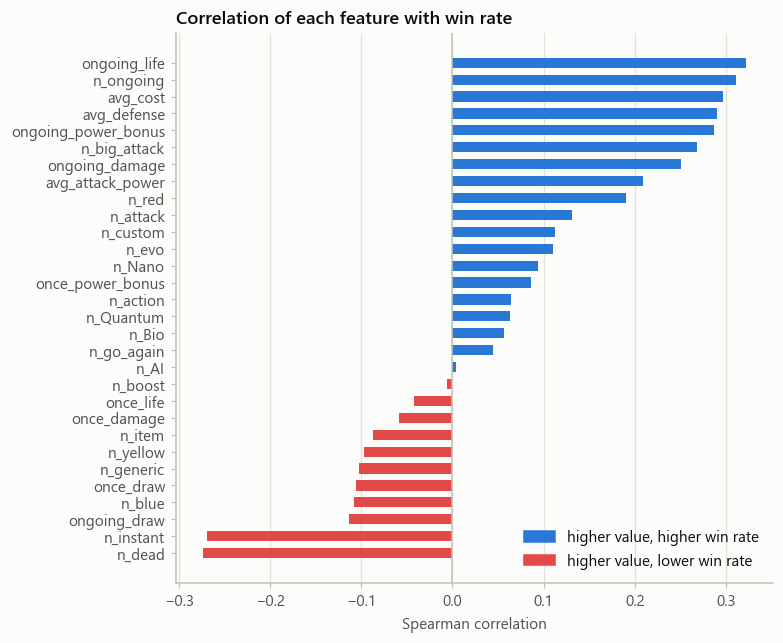

In [5]:
constant = [f for f in teklo.FEATURES if data[f].nunique() == 1]
print("Always the same value, left out:", constant)
corr = data[[f for f in teklo.FEATURES if f not in constant]].corrwith(data.win_rate, method="spearman").sort_values()

fig, ax = plt.subplots(figsize=(7, 6.5))
ax.barh(corr.index, corr.values, color=[BLUE if v > 0 else RED for v in corr], height=0.6)
ax.axvline(0, color=AXIS, linewidth=1)
ax.set_title("Correlation of each feature with win rate")
ax.set_xlabel("Spearman correlation")
ax.grid(axis="y", visible=False)
ax.legend(handles=[Patch(color=BLUE, label="higher value, higher win rate"),
                   Patch(color=RED, label="higher value, lower win rate")], loc="lower right")
plt.show()

Every-turn effects (`ongoing_life`, `ongoing_power_bonus`, `ongoing_damage`) and the number of items and Evos that have one go with higher win rates. Cards the simulator can't use (`n_dead`) and instants go with lower ones.
These are hints, not proof: notebook 03 checks what a model that sees all features at once actually relies on.

## 4. Freeze a test set

Split once, save the split, and don't look at the test decks until the end of notebook 03.
If you tune a model while peeking at the test set, its score stops being an honest estimate.

In [6]:
rng = np.random.default_rng(7)
data["split"] = np.where(rng.random(len(data)) < 0.8, "train", "test")
train = data[data.split == "train"]
data.split.value_counts()

split
train    646
test     154
Name: count, dtype: int64

## 5. Features that match the game

The first version of these features added each effect up over the whole deck: total power bonus, total life gained, and so on.
It scored a cross-validated R² of about 0.37.

But in this game, *when* an effect happens matters. An item that gives +1{p} pays off every turn; an action that gives +1{p} pays off once.
The current features split each total by timing (`ongoing_*` and `once_*`), and count the cards that do nothing in this simulator (`n_dead`).
Same data, same model, only the description of the decks changes
(scored with 5-fold cross-validation on the training decks, so the test set stays untouched):

In [7]:
cv = KFold(n_splits=5, shuffle=True, random_state=0)


def cv_r2(frame, columns):
    model = HistGradientBoostingRegressor(random_state=0)
    return cross_val_score(model, frame[columns], frame.win_rate, cv=cv, scoring="r2").mean()


# First try: one total per effect, whichever card it comes from
first_try = train.copy()
for e in EFFECTS:
    first_try[f"sum_{e}"] = first_try[f"once_{e}"] + first_try[f"ongoing_{e}"]
first_cols = [f for f in teklo.FEATURES
              if not f.startswith(("once_", "ongoing_")) and f not in ("n_ongoing", "n_dead", "n_big_attack")]
first_cols += [f"sum_{e}" for e in EFFECTS]

pd.Series({
    "First try: one total per effect": cv_r2(first_try, first_cols),
    "Effects split by timing, plus n_dead and n_big_attack": cv_r2(train, teklo.FEATURES),
}, name="cross-validated R²").round(3).to_frame()

,cross-validated R²
First try: one total per effect,0.375
"Effects split by timing, plus n_dead and n_big_attack",0.658


Feature engineering is mostly this: describing the data in the terms the game actually uses.

## 6. The leakage trap

v1's model used `avg_turns`, `avg_final_life` and `consistency_score`. Those are measured **from the games**.
To know them for a new deck you would have to play its games first, and then you would already know its win rate.

Our simulation also recorded two outcome columns, `avg_turns` and `avg_life_diff`. Watch what happens if they slip into the features
(same cross-validation as above):

In [8]:
pd.Series({
    "Deck list only (honest)": cv_r2(train, teklo.FEATURES),
    "Deck list + game outcomes (leaky)": cv_r2(train, teklo.FEATURES + ["avg_turns", "avg_life_diff"]),
}, name="cross-validated R²").round(3).to_frame()

,cross-validated R²
Deck list only (honest),0.658
Deck list + game outcomes (leaky),0.968


The leaky model scores higher, but only because `avg_life_diff` is nearly the answer written another way.
It could never be used on a new deck. Ask this of every column: **would I have this value at prediction time?**

## 7. Save the dataset

In [9]:
columns = ["deck_id", *teklo.FEATURES, "win_rate", "games", "wins", "draws", "avg_turns", "avg_life_diff", "split"]
data[columns].to_csv(DATA / "teklo_decks.csv", index=False)
(DATA / "features.json").write_text(json.dumps(teklo.FEATURES, indent=2))
print(f"Saved {len(data)} rows × {len(columns)} columns to {(DATA / 'teklo_decks.csv').relative_to(ROOT).as_posix()}")

Saved 800 rows × 40 columns to data/v2/teklo_decks.csv


The outcome columns stay in the file because they are useful for analysis.
`features.json` lists what models are allowed to use.

Next: **03 · Train and evaluate**.